# Seven-qubit processor (A. Dahima): a Quantcore-PDK rebuild, step by step

**Source:** Atharve Dahima, *7-qubit-superconducting-processor*, `simon_7qubit_complete_chip.py` (the routed
end-of-lecture chip) and its exported mask `seven_qubit_chip_mask.gds`,
<https://github.com/atharveeee-netizen/7-qubit-superconducting-processor>. The README badge says MIT but the repo has no
LICENSE file; it is rebuilt regardless (decision, 2026-11-03), credited here and distributed under the GPL. A depth-1 clone was
read on 2026-11-03 in `build/external/7-qubit-superconducting-processor` (read only, never executed); the mask is in
`build/external/7q/`. Spec: `docs/designs/community/seven_qubit_processor.md`.

**What the chip is:** 7 pocket transmons in a U chain Q0–Q1–Q3–Q4–Q5–Q2–Q6 on a 10 × 10 mm chip.
- Six are `TransmonPocket6`; Q4 is a `TransmonPocketCL` with a charge line.
- Six meandered buses join neighbours (Metal `RouteMeander`, default 7 mm).
- Six meanders run from the qubits' readout pads straight to wirebond pads (no resonators, no feedline).
- The exported mask carries Quantum Metal's default GDS cheese: 25 µm square holes on a 100 µm pitch over the whole
  ground, 25 µm clear of all geometry (`no_cheese` buffer), with a ≈ 190 µm band clear along the chip edge.

README targets: f_q 4.8–5.2 GHz, α −280…−330 MHz, f_r 6.8–7.4 GHz in 100 MHz steps, g 50–70 MHz. The source's own
Q3D/LOM run on Q4 gives C_Σ 74.70 fF, L_J 12.305 nH and f_q 4.974 GHz.

**This notebook rebuilds the chip in the Quantcore PDK; it is not a replica.** What the rebuild keeps and what the PDK
changes:

| topic | source | this rebuild |
|---|---|---|
| die and frame | 10 × 10 mm Metal chip centred on (0, 0), no frame | PDK frame on the same die (Designer = source + (5000, 5000) µm, then centred), device ID `SQP-7Q` |
| stack | silicon (README) | PDK sapphire 650 µm, εr 10.25 |
| qubits | Metal `TransmonPocket6` / `TransmonPocketCL` (pads 455 × 90 µm, gap 30, pocket 650 × 650) | the same cells and options through the `metal:` wrappers, same positions and orientations |
| junctions | lumped L_J 10–12.3 nH | Quantcore trilayer junctions sized for a staggered 4.80–5.20 GHz plan (`size_junction`); R_n is flagged, not retuned |
| readout | a meander galvanically joined to a pad per qubit | a λ/4 hanger per qubit on one ∩ feedline round the chain, 6.8–7.3 GHz |
| buses | six 7 mm `RouteMeander`s | the same lengths: two drawn serpentines (outer) and four qcc meanders |
| pads | six readout wirebond pads | three `LaunchpadWirebond`s (feed in, feed out, Q4's charge line), **`frame.pad_edge` = 100 µm from the die edge** (PDK pad rule) |
| placement | the chain sits above the chip centre | **PDK**: the chip core (qubits, buses, readouts, feedline) is centred in the die |
| cheese | Metal's GDS cheese in the exported mask | **the original's cheese**: Metal's rule drawn by the build (`cheese` = `metal_cheese_rule()`) and kept in the mask; no PDK band |

**How this notebook goes.** First the **Design**: the chip is laid out one segment at a time, each segment its own
cell with a picture of the chip so far — the die with Metal's cheese rule, the three launchpads, the ∩ feedline round the chain, the
seven pocket transmons with their sized trilayer junctions, the six λ/4 hanger readouts, the six λ/2 buses of the U
chain, Q4's charge line, and then the whole chip (the sim groups and targets, the centring of the core, the save). Then the same steps as the Flow strip of the Quantcore
KLayout plugin: **Check** (DRC, netlist) → **LOM** (simulation and plots) → **Simulate** (export to HFSS, the
component simulation, the eigenmode simulation, the full-wave run) → **Results** (plots, the values, FEM against the
LOM, a feedback step and the iteration to a target) → **Fab**.

**Nothing here solves on its own.** The switches (the code cell after Setup) are off (`RUN_FEM = False`): FEM results
are loaded when a solve has been kept, otherwise each FEM cell says what would appear. The notebook before this
rewrite (the layout in a few cells, with its outputs) is kept as `seven_qubit_processor.v1.ipynb`; both save the same
`seven_qubit_processor.json`.

## Setup

The notebook runs from the repository root. `_common` holds the table, snapshot and PDK helpers shared by the design
notebooks. `LIVE` follows `QCC_LIVE`: with KLayout open, every change below shows up live; with `QCC_LIVE=0` (tests,
batch runs) the snapshots are rendered headless.

`sizing_md` tabulates the junction sizing; `center_core` centres the chip's core, leaving out the pads (pinned to the
die edge) and the charge-line lead that runs to one of them.

**The switches** (next cell): `RUN_FEM` solves the FEM jobs in AEDT 2024 R1 or newer, one after the other (a new
non-graphical AEDT unless `AEDT_MODE` says otherwise; an AEDT you have open is never touched); `RESOLVE` solves again
even when kept results match; `FEM_FAST` exports with the library's fast test settings (minutes, values not
converged); `MAX_ITER` caps the feedback iterations towards the targets.

In [2]:
%config InlineBackend.figure_formats = ["png"]
import os, sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(ROOT)                                   # paths below are relative to the repo root
sys.path.insert(0, str(ROOT / "examples" / "designs"))
from _common import *                            # tables, snapshots, PDK helpers
from quantcore_circuits.designer import Designer
from quantcore_circuits.circuit.bridges import size_junction, tl_resonator
from quantcore_circuits.layouts.registry import trilayer_junction

LIVE = os.environ.get("QCC_LIVE", "1") == "1"   # live KLayout by default; QCC_LIVE=0 for batch runs
OUT = Path("examples/designs/community")
OUT.mkdir(parents=True, exist_ok=True)


def sizing_md(sizing):
    """Trilayer junction sizing (``circuit.bridges.size_junction``) against the PDK junction rule."""
    rows = ["| qubit | f_q target (GHz) | C_Σ (fF) | L_J (nH) | R_n (kΩ) | drawn f_q (GHz) | R_n in 40–50 kΩ |",
            "|---|---|---|---|---|---|---|"]
    for name, s in sizing.items():
        rows.append(f"| {name} | {s.f_q_GHz:.3f} | {s.c_sigma_fF:.1f} | {s.lj_nH:.2f} | {s.rn_kohm:.1f} | "
                    f"{s.f_q_drawn_GHz:.3f} | {'yes' if s.rn_in_window else 'no'} |")
    return "\n".join(rows)


def center_core(d, skip=(), tol=50.0):
    """Centre the chip's core (every instance and route except ``skip``) in the die: shift the whole design so the
    core's bounding box is centred (pads pinned to an edge keep their edge distance). Returns the shift (µm)."""
    from kqcircuits.pya_resolver import pya
    from quantcore_circuits.assembly.sidecar import sidecar_dict

    side = sidecar_dict(rebuild(d), overlays=False)
    box = pya.DBox()
    for name, inst in side["instances"].items():
        if name not in skip and inst.get("bbox"):
            box += pya.DBox(*inst["bbox"])
    for name, route in side["routes"].items():
        if name not in skip:
            for x, y in route.get("polyline") or []:
                box += pya.DPoint(x, y)
    x0, y0, x1, y1 = d.design.chip.box
    dx, dy = round((x0 + x1) / 2 - box.center().x, 1), round((y0 + y1) / 2 - box.center().y, 1)
    if abs(dx) <= tol and abs(dy) <= tol:
        return (0.0, 0.0)
    translate_design(d, dx, dy)
    return (dx, dy)

In [3]:
RUN_FEM = False        # True (or a set such as {"q3d_cmatrix"}): solve the FEM jobs in AEDT 2024 R1+, one at a time
RESOLVE = False        # True (or a set of analyses): solve again even when kept results match
FEM_FAST = True        # True: the library's fast test settings (minutes, not converged); False: the settings as written
AEDT_MODE = "batch"    # "batch" (no window) | "gui" (a new AEDT window, left open) | "attach" (the AEDT you have open)
MAX_ITER = 3           # feedback iterations towards the targets (Results 5)

## The Quantcore PDK this chip uses

The PDK facts this chip relies on. Every rule is applied by the library, not by this notebook: the frame and the cheese by
the chip build, the pad rule by `edge=`, the junctions by `trilayer_junction`, the design warnings by the DRC.

In [4]:
display(Markdown(pdk_facts_md()))

| PDK rule | value |
|---|---|
| process | `quantcore_nb_sapphire_v1` v3 |
| stack | sapphire 650 µm, εr 10.25, Nb film (λ_L 0.09 µm) |
| CPW default | centre 10 µm, gap 6 µm, bend radius 100 µm |
| die frame | standard die 7.5 × 7.5 mm; L dicing markers (1000/0, 25 µm wide), 3 × 3 alignment grids (1001/0) in 500 µm corner areas, boundary 100/0, device ID |
| pad rule | bond pads / launchers: outer etch edge **100 µm** (`frame.pad_edge`) from the die edge (`edge="auto"`) |
| junctions | Nb/AlOx/Nb trilayer, Nb Δ 1.4 meV, R_n 40–50 kΩ (nominal 45 kΩ = 0.5 × 0.6 µm), C_J 50 fF/µm²; fingers 2/0 + 4/0, spacer 50/0 (+ 51–53/0 dose gradient) |
| qubit band | f_q 4–8 GHz (outside: DRC design warning `pdk_fq`) |
| cheese | the original design's own if it has one, else the PDK band: 5 µm squares, 20 µm gaps, 3 rows around the 3/0 keep-outs (chip param `cheese`: auto / pdk / original) |
| 3/0 keep-out | filled second-metal etch: routes CPW footprint + 10 µm, components etch bbox + 24 µm (or the cell's own) |
| corner rounding | fab only: r = 0.25 × the shortest dimension, ≤ 10 µm |

# Design: the layout, one segment at a time

The chip is built the way a designer would lay it out by hand: the die, the bond pads, the readout, the qubits, the
coupling, the control lines, and then the whole chip. Each segment is one cell with one picture of the chip so far
(and, live, KLayout redraws after every cell). A route joins two ports, or a port and a hanger on another route, so the feedline is drawn as soon as its
two pads exist (segment 3), the readouts and buses once the qubits are there (segments 5–6). Every position is a source
coordinate + (5000, 5000) µm until the centring in segment 8, so the order changes nothing.

| segment | what is placed here |
|---|---|
| 1 | the 10 × 10 mm die with the PDK frame and Metal's GDS cheese rule (the original's) |
| 2 | three launchpads: the feedline's input and output (west / east) and Q4's charge line (south) |
| 3 | the readout line: the ∩ feedline from LP_IN round the chain to LP_OUT |
| 4 | the seven pocket transmons (six `TransmonPocket6`, Q4 a `TransmonPocketCL`), junctions sized for 4.80–5.20 GHz |
| 5 | the six λ/4 hanger readouts (Q4 has none), 6.8–7.3 GHz, on the inner side of the feedline |
| 6 | the coupling: the six λ/2 buses of the U chain Q0–Q1–Q3–Q4–Q5–Q2–Q6 |
| 7 | the control routing: Q4's charge line to LP_CL |
| 8 | the whole chip: the sim groups and targets, the centring of the core, the save |

## Design 1 · The die and its frame

`Designer(name, box=...)` opens an empty chip. The source's 10 × 10 mm chip is kept, so Designer = source +
(5000, 5000) µm (until the centring in Design 8). The PDK draws the frame round it: L dicing markers (1000/0), 3 × 3
alignment grids (1001/0), the chip boundary (100/0) and the device ID (`name_chip`) on a free edge.

**Cheese: the original's.** The source's exported mask `seven_qubit_chip_mask.gds` carries Quantum Metal's default GDS
cheese (its `QGDSRenderer` defaults: 25 µm squares every 100 µm, 25 µm clear of all geometry, none near the chip
edge). The original wins over the PDK band: `chip={"cheese": metal_cheese_rule()}` hands the build Metal's rule
(25 µm squares every 100 µm, 25 µm clear of the 3/0 keep-outs, none within 200 µm of the die edge), and the build
draws it instead of the band.

chip cheese rule: {'size': 25.0, 'gap': 75.0, 'rows': 1000, 'clearance': 25.0, 'edge': 200.0}


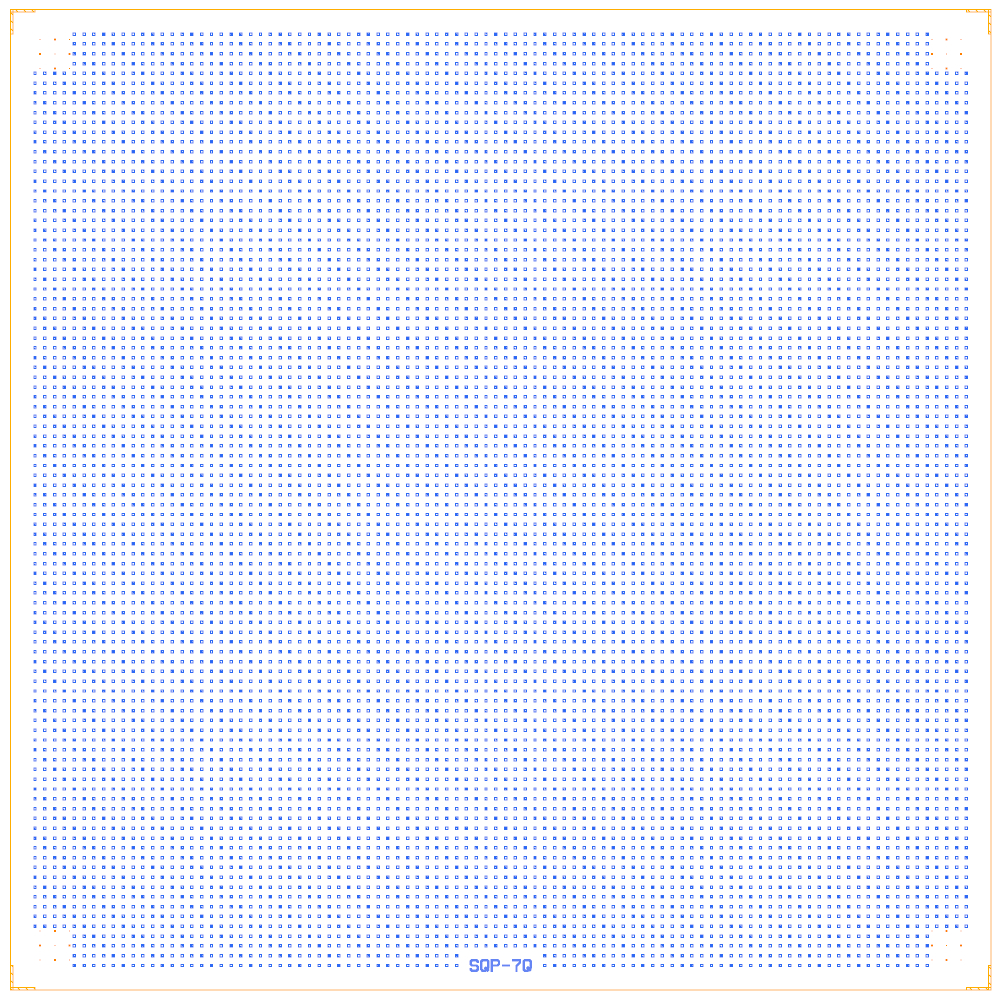

**On the chip so far:** 0 pads · 0 qubits · 0 other components · 0 routes · 0 declared couplings. **This step added** nothing new to the layout.

WindowsPath('examples/designs/community/seven_qubit_processor_die.png')

In [5]:
X0 = Y0 = 5000.0                                   # the source's 10 × 10 mm chip is centred on (0, 0)
d = Designer("seven_qubit_processor", box=(0, 0, 10000, 10000), chip={"name_chip": "SQP-7Q", "cheese": metal_cheese_rule()},
             live=LIVE)
print("chip cheese rule:", d.design.chip.params["cheese"])
layout_step(d, OUT / "seven_qubit_processor_die.png", size=(1000, 1000), width=360)

## Design 2 · Bond pads: three launchpads and the PDK pad rule

The source has six readout wirebond pads; the rebuild replaces its galvanic readouts by a feedline (Design 3), so it needs
three `metal:LaunchpadWirebond`s:
- **LP_IN / LP_OUT**, the feedline's input and output, on the west and east edges at the height where the feedline legs
  end (`PAD_Y`), facing in;
- **LP_CL**, Q4's charge line, on the south edge below Q4, facing north.

The PDK puts every bond pad with the outer edge of its etch **`frame.pad_edge` = 100 µm from the die edge**:
`edge="w"` / `"e"` / `"s"` slides a pad perpendicular to that edge until it holds and keeps its position along the edge.

| pad | cell / launcher | nearest die edge | outer etch → die edge (µm) | PDK rule |
|---|---|---|---|---|
| LP_IN | `metal:LaunchpadWirebond` | w | 100.0 | ✓ |
| LP_OUT | `metal:LaunchpadWirebond` | e | 100.0 | ✓ |
| LP_CL | `metal:LaunchpadWirebond` | s | 100.0 | ✓ |

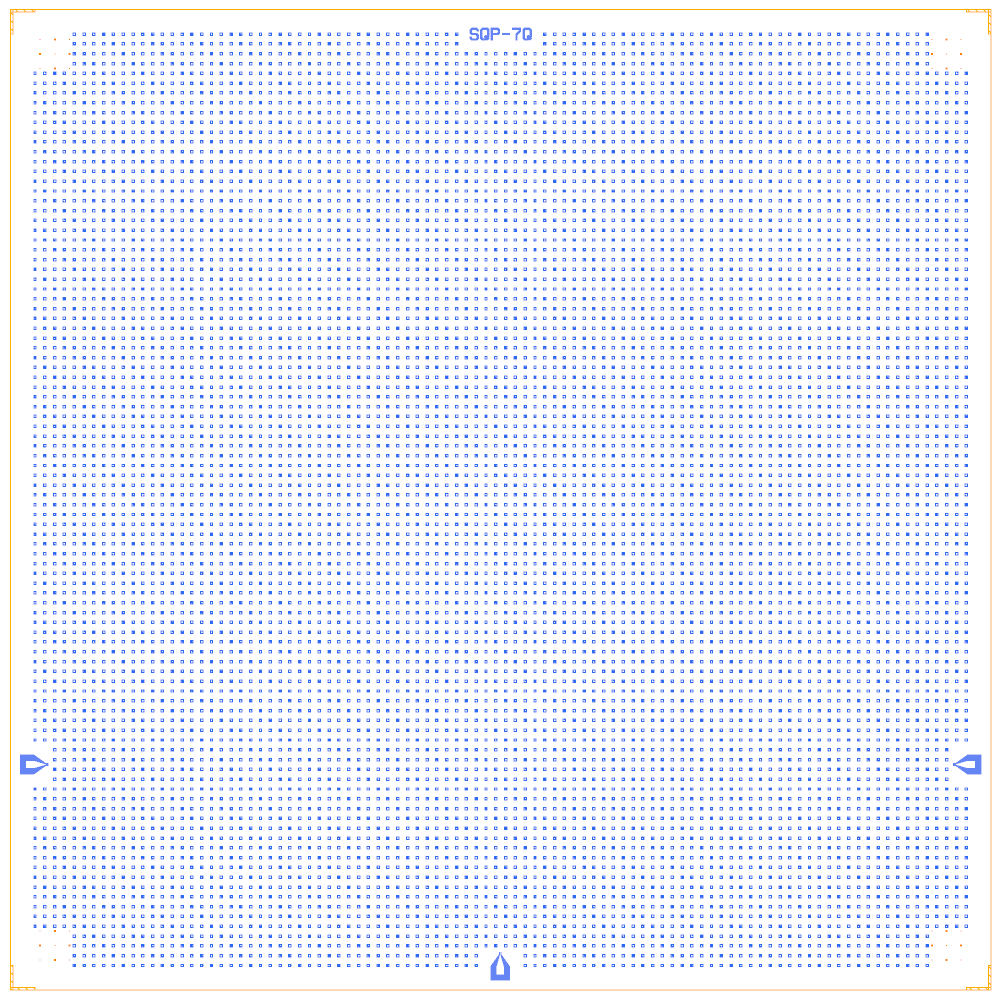

**On the chip so far:** 3 pads · 0 qubits · 0 other components · 0 routes · 0 declared couplings. **This step added** 3 component(s) `LP_IN`, `LP_OUT`, `LP_CL`.

WindowsPath('examples/designs/community/seven_qubit_processor_s2_pads.png')

In [6]:
FL_X, FL_TOP, PAD_Y = 1000.0, 8700.0, 2300.0       # ∩ feedline: legs at x = 1000 / 9000, top at y = 8700, feet at 2300
with d.batch():
    lp_in = d.add("LP_IN", "metal:LaunchpadWirebond", at=(FL_X, PAD_Y), rot=0, edge="w")
    lp_out = d.add("LP_OUT", "metal:LaunchpadWirebond", at=(10000 - FL_X, PAD_Y), rot=180, edge="e")
    lp_cl = d.add("LP_CL", "metal:LaunchpadWirebond", at=(X0 - 5, PAD_Y), rot=90, edge="s")
rebuild(d)
display(Markdown(pads_md(d)))
layout_step(d, OUT / "seven_qubit_processor_s2_pads.png", size=(1000, 1000), width=360)

## Design 3 · Readout: the ∩ feedline

**The feedline** runs from LP_IN's `tie` east to the left leg, up, across the top and down the right leg to LP_OUT: a ∩
round the chain, so every readout hangs on its inner side. Its legs and top
run are fixed coordinates (`FL_X`, `FL_TOP`, `PAD_Y`), so it needs no qubit and comes first.

FL: 21858.3 µm


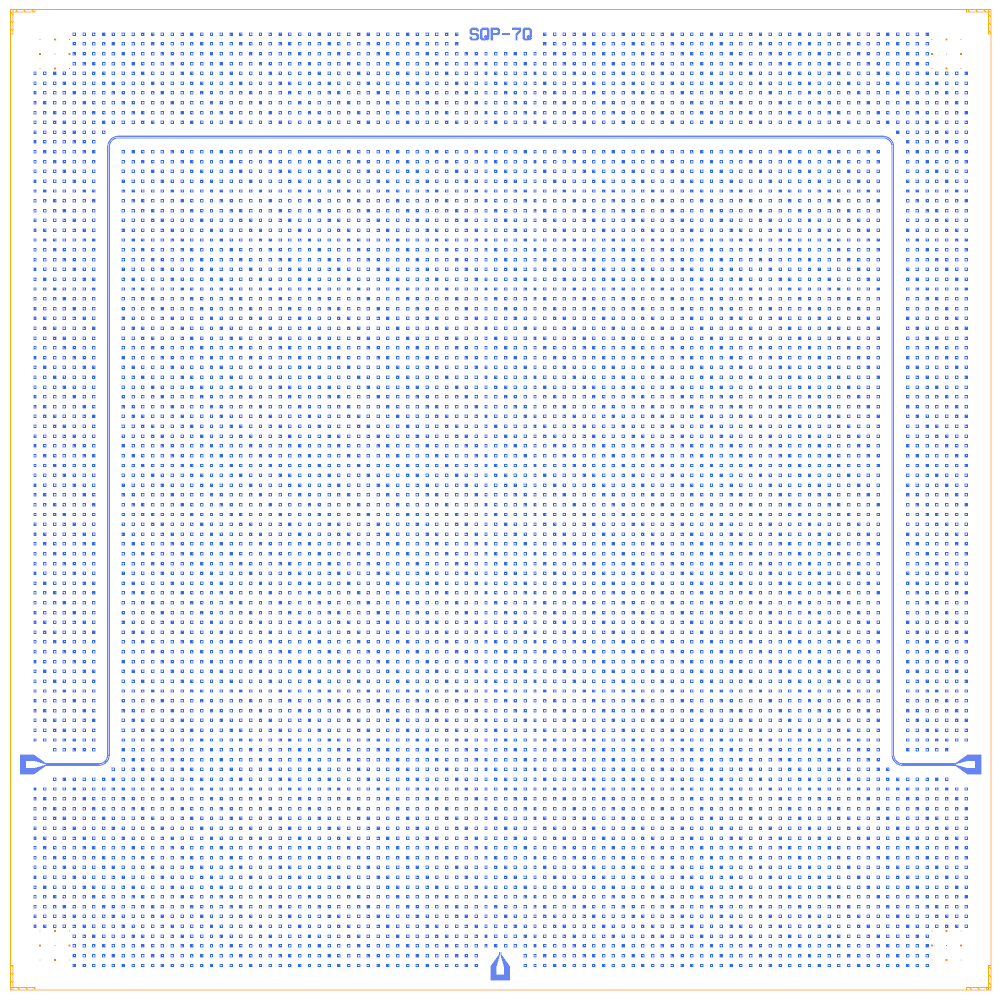

**On the chip so far:** 3 pads · 0 qubits · 0 other components · 1 routes · 0 declared couplings. **This step added** 1 route(s) `FL`.

WindowsPath('examples/designs/community/seven_qubit_processor_s3_feedline.png')

In [7]:
fl = d.route("FL", lp_in.tie, lp_out.tie,
             nodes=[(FL_X, PAD_Y), (FL_X, FL_TOP), (10000 - FL_X, FL_TOP), (10000 - FL_X, PAD_Y)])
rebuild(d)
print(f"FL: {fl.length:.1f} µm")
layout_step(d, OUT / "seven_qubit_processor_s3_feedline.png", size=(1000, 1000), width=360)

## Design 4 · Qubit placement: seven pocket transmons with trilayer junctions

**Junction sizing.** The source gives no per-qubit L_J, only the README window. The rebuild staggers the qubits over
4.80–5.20 GHz and sizes each Quantcore trilayer junction with `circuit.bridges.size_junction(f_q, C_Σ)` on the LOM C_Σ
of the pocket (63.5 fF; the source's Q3D gives 74.7 fF). `trilayer_junction(cell, lj_nH=...)` turns the L_J into the
cell parameters that draw the junction (fingers on 2/0 and 4/0, spacer 50/0 with the 51–53/0 gradient) and the values
the LOM uses.

At this C_Σ a 4.8–5.2 GHz qubit needs E_J/h ≈ 12–14 GHz, so R_n comes out 86–102 kΩ, **outside the PDK window of
40–50 kΩ** (the table says which). Inside the window the qubits would sit at ≈ 6.5–7 GHz, next to the readouts.
Following the project rule (values are flagged, never retuned), the plan stays and the DRC reports `pdk_rn`.

In [8]:
C_SIGMA = 63.5      # fF: LOM C_Σ of the pocket in its readout group (source Q3D of Q4: 74.70 fF); sizes every junction
F_Q = dict(Q0=4.80, Q1=5.10, Q3=4.85, Q4=5.15, Q5=4.90, Q2=5.20, Q6=4.95)   # README window 4.8–5.2 GHz, staggered
SIZING = {q: size_junction(f, C_SIGMA) for q, f in F_Q.items()}
display(Markdown(sizing_md(SIZING)))

| qubit | f_q target (GHz) | C_Σ (fF) | L_J (nH) | R_n (kΩ) | drawn f_q (GHz) | R_n in 40–50 kΩ |
|---|---|---|---|---|---|---|
| Q0 | 4.800 | 63.5 | 15.31 | 102.3 | 4.800 | no |
| Q1 | 5.100 | 63.5 | 13.65 | 91.2 | 5.137 | no |
| Q3 | 4.850 | 63.5 | 15.01 | 100.3 | 4.800 | no |
| Q4 | 5.150 | 63.5 | 13.41 | 89.6 | 5.137 | no |
| Q5 | 4.900 | 63.5 | 14.72 | 98.4 | 4.915 | no |
| Q2 | 5.200 | 63.5 | 13.16 | 88.0 | 5.245 | no |
| Q6 | 4.950 | 63.5 | 14.44 | 96.5 | 4.915 | no |

**The qubits.** The source's pockets (pads 455 × 90 µm, gap 30 µm, pocket 650 × 650 µm) at the source positions and
orientations. The connection-pad corners (`loc_W`, `loc_H`) are chosen so each bus pad faces its neighbour (the
source's corners send Q0–Q1 and Q2–Q6 round the pockets). Q4 is a `TransmonPocketCL`: two 50 × 30 µm bus pads and a
charge line (`Charge_Line` pin).

<metal:TransmonPocketCL Q4 ports=['Charge_Line', 'bus_left', 'bus_right', 'squid_a', 'squid_b']>


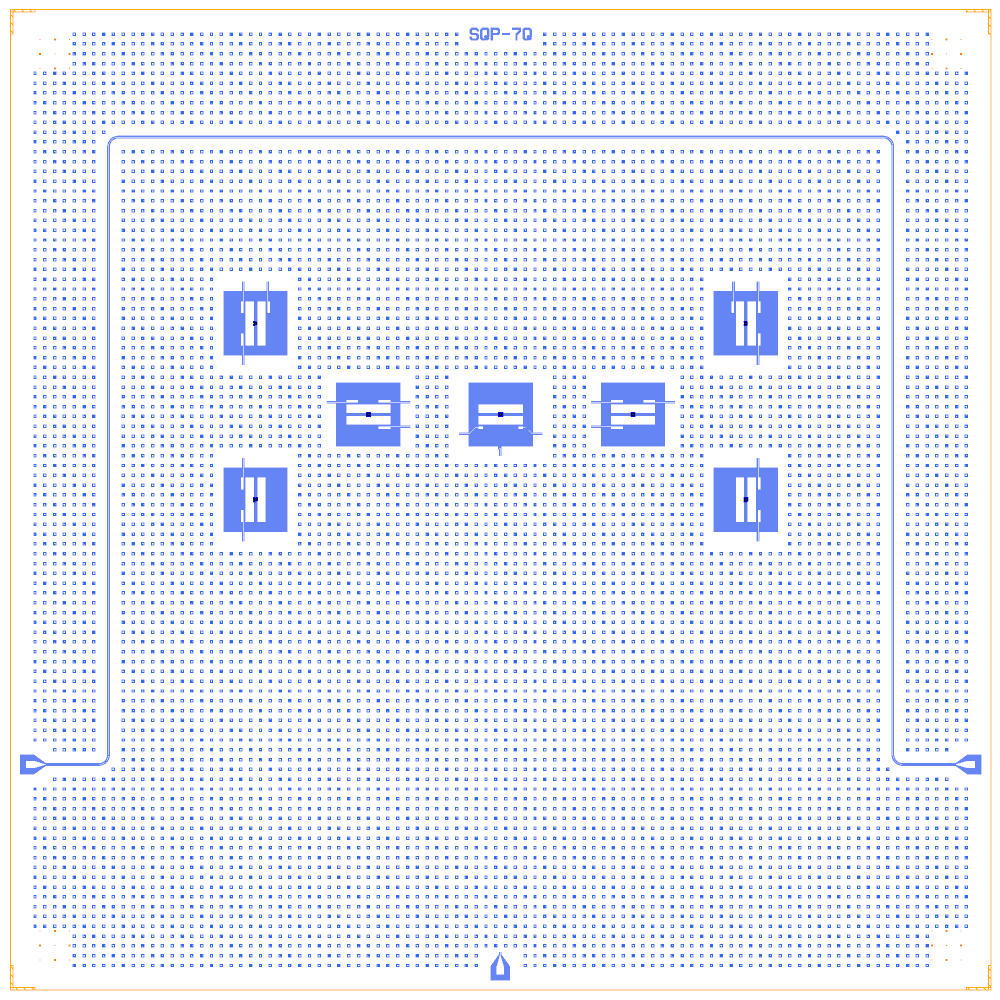

**On the chip so far:** 3 pads · 7 qubits · 0 other components · 1 routes · 0 declared couplings. **This step added** 7 component(s) `Q0`, `Q1`, `Q3`, `Q5`, `Q2`, `Q6`, `Q4`.

WindowsPath('examples/designs/community/seven_qubit_processor_components.png')

In [9]:
POCKET = dict(pad_width=455, pad_height=90, pad_gap=30, pocket_width=650, pocket_height=650)
UP, DN = 1, -1                                     # rot 90 (Q0, Q1, Q2, Q6): loc_W = +1 top, −1 bottom
L_, R_ = 1, -1                                     #                         loc_H = +1 left, −1 right
QUBITS = {  # name: ((x, y) source µm, rot, connection_pads)
    "Q0": ((-2500, 0), 90, dict(bus_top=dict(loc_W=UP, loc_H=L_), readout=dict(loc_W=DN, loc_H=L_))),
    "Q1": ((-2500, 1800), 90, dict(bus_bot=dict(loc_W=DN, loc_H=L_), bus_right=dict(loc_W=UP, loc_H=R_),
                                    readout=dict(loc_W=UP, loc_H=L_))),
    "Q3": ((-1350, 870), 0, dict(bus_left=dict(loc_W=-1, loc_H=1), bus_right=dict(loc_W=1, loc_H=-1),
                                  readout=dict(loc_W=1, loc_H=1))),
    "Q5": ((1350, 870), 0, dict(bus_left=dict(loc_W=-1, loc_H=-1), bus_right=dict(loc_W=1, loc_H=1),
                                 readout=dict(loc_W=-1, loc_H=1))),
    "Q2": ((2500, 1800), 90, dict(bus_bot=dict(loc_W=DN, loc_H=R_), bus_left=dict(loc_W=UP, loc_H=L_),
                                   readout=dict(loc_W=UP, loc_H=R_))),
    "Q6": ((2500, 0), 90, dict(bus_top=dict(loc_W=UP, loc_H=R_), readout=dict(loc_W=DN, loc_H=R_))),
}
CL = dict(make_CL=True, cl_gap=6, cl_width=10, cl_length=20, cl_ground_gap=6, cl_pocket_edge="50", cl_off_center=0)
Q4_PADS = dict(bus_left=dict(loc_W=-1, loc_H=-1, pad_width=50, pad_height=30),
               bus_right=dict(loc_W=1, loc_H=-1, pad_width=50, pad_height=30))
q = {}
with d.batch():
    for name, ((x, y), rot, pads) in QUBITS.items():
        params, jj = trilayer_junction("metal:TransmonPocket6", lj_nH=SIZING[name].lj_nH)
        q[name] = d.add(name, "metal:TransmonPocket6", at=(X0 + x, Y0 + y), rot=rot, junction=jj,
                        connection_pads=pads, **POCKET, **params)
    params, jj = trilayer_junction("metal:TransmonPocketCL", lj_nH=SIZING["Q4"].lj_nH)
    q["Q4"] = d.add("Q4", "metal:TransmonPocketCL", at=(X0, Y0 + 870), junction=jj, connection_pads=Q4_PADS,
                    **POCKET, **CL, **params)
print(q["Q4"])
layout_step(d, OUT / "seven_qubit_processor_components.png", size=(1000, 1000), width=360)

## Design 5 · Readout: six λ/4 hanger readouts

**Readouts.** Each readout is a λ/4 route from the qubit's readout pad: meander → a 250 µm section along the feedline
with a 6 µm ground strip → short to ground, at the README's 6.8–7.3 GHz.
- `fl.hanger(near=(x, y), length=250, side="right", ...)` centres the coupled section at the feedline point nearest
  (x, y): on the left leg for Q0/Q1, on the top for Q3/Q5, on the right leg for Q2/Q6. Placing it by position, not by
  arclength from LP_IN, keeps it in place when the pads or the feedline's ends move. `direction` sets which end of the
  coupled section is shorted.
- The lengths are the PDK CPW's v_ph / 4f, minus 6.7 % for the C_g and hanger pull seen in the LOM (`tl_resonator`
  gives v_ph of the 10/6 µm CPW on sapphire).

Q4 has no readout pad (its two bus pads and its charge line are its ports), so six qubits get a readout. The router adds one KQC `Meander` for whatever
each length leaves over its path; R_Q3 and R_Q5 first follow their waypoints (`VIA`) round the inner buses.

{'Q0': 4323.2, 'Q1': 4260.5, 'Q3': 4199.7, 'Q5': 4140.5, 'Q2': 4083.0, 'Q6': 4027.1}


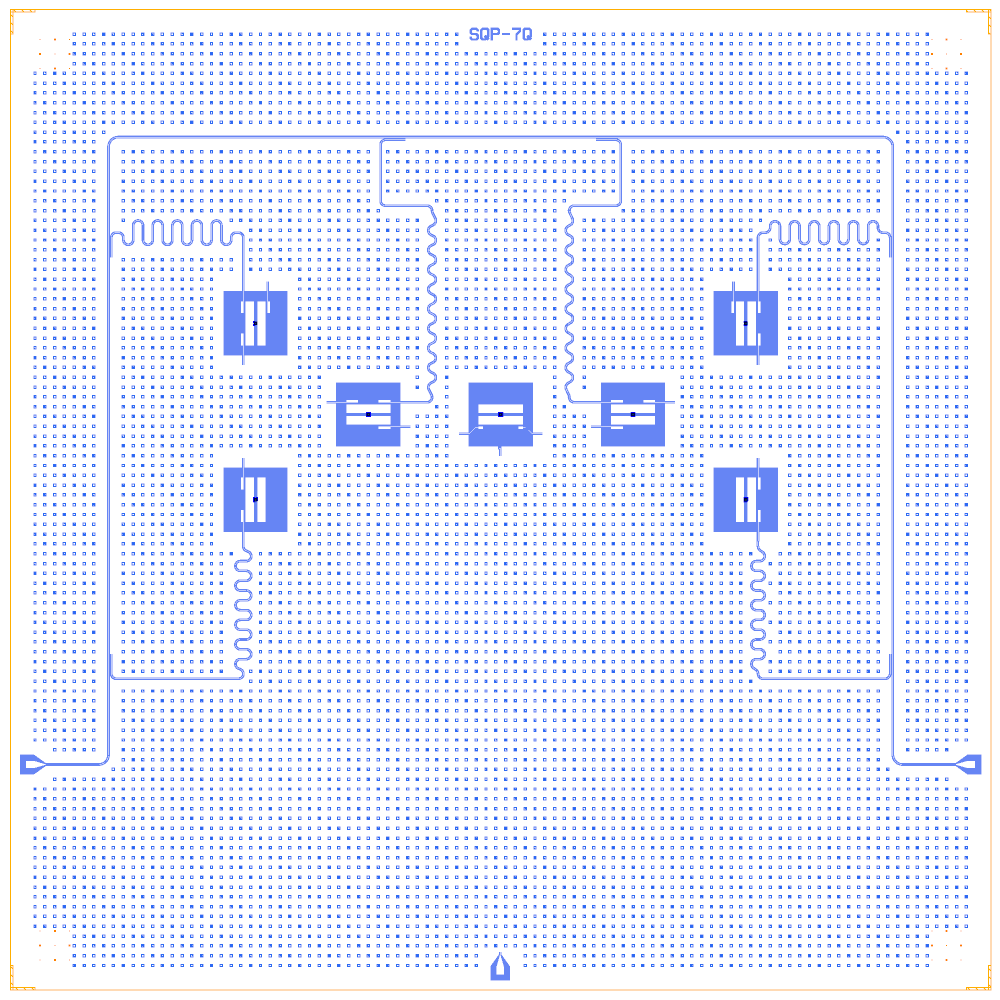

**On the chip so far:** 3 pads · 7 qubits · 0 other components · 7 routes · 0 declared couplings. **This step added** 6 route(s) `R_Q0`, `R_Q1`, `R_Q3`, `R_Q5`, `R_Q2`, `R_Q6`.

WindowsPath('examples/designs/community/seven_qubit_processor_s5_readouts.png')

In [10]:
F_R = dict(Q0=6.8, Q1=6.9, Q3=7.0, Q5=7.1, Q2=7.2, Q6=7.3)                   # README 6.8–7.4 GHz, 100 MHz steps
VP = tl_resonator(4500, 10, 6)["vp_m_s"]           # PDK stack (sapphire): phase velocity of the 10/6 µm CPW
L_RO = {k: round(VP / (4 * f * 1e9) * 1e6 * 0.933, 1) for k, f in F_R.items()}  # λ/4, −6.7 %: C_g + hanger pull (LOM)
HG = dict(length=250, side="right", ground_gap=6, end="short")
NEAR = {"Q0": ((FL_X, 3300), "forward"), "Q1": ((FL_X, 7600), "backward"), "Q3": ((3900, FL_TOP), "forward"),
        "Q5": ((6100, FL_TOP), "backward"), "Q2": ((10000 - FL_X, 7600), "forward"),
        "Q6": ((10000 - FL_X, 3300), "backward")}
VIA = {"Q3": [(4300, 5995), (4300, 8000), (3775, 8000)], "Q5": [(5700, 5995), (5700, 8000), (6225, 8000)]}
with d.batch():
    for n, (at, direction) in NEAR.items():
        d.route(f"R_{n}", q[n].readout, fl.hanger(near=at, direction=direction, **HG), meander=L_RO[n], r=50,
                nodes=VIA.get(n))
print(L_RO)
layout_step(d, OUT / "seven_qubit_processor_s5_readouts.png", size=(1000, 1000), width=360)

## Design 6 · Coupling: six λ/2 buses

**Buses.** The source's buses are 7 mm `RouteMeander`s (Metal's default length; the source sets none), λ/2 resonators
between two bus pads.
- The two outer buses (Q0–Q1, Q2–Q6) are drawn serpentines (`nodes=SERP`, 40 µm bends) whose drawn path is 6994 µm:
  the router's own meander in that 950 µm gap crosses itself, so the path is given and the length pinned to it
  (`L_SERP`, 0.05 µm over the drawn path). The router puts so small a leftover into the free corners (their bend
  radius trimmed by at most 5 %) and draws no meander, so each serpentine is exactly its waypoints (an earlier
  router turned the 0.05 µm into a near-straight zigzag).
- The four inner buses are qcc meanders of 7000 µm on waypoints. Their waypoint paths are much shorter, so each
  gets one KQC `Meander` for the leftover, with no more turns than keep each turn at least its 50 µm bend radius
  wide.

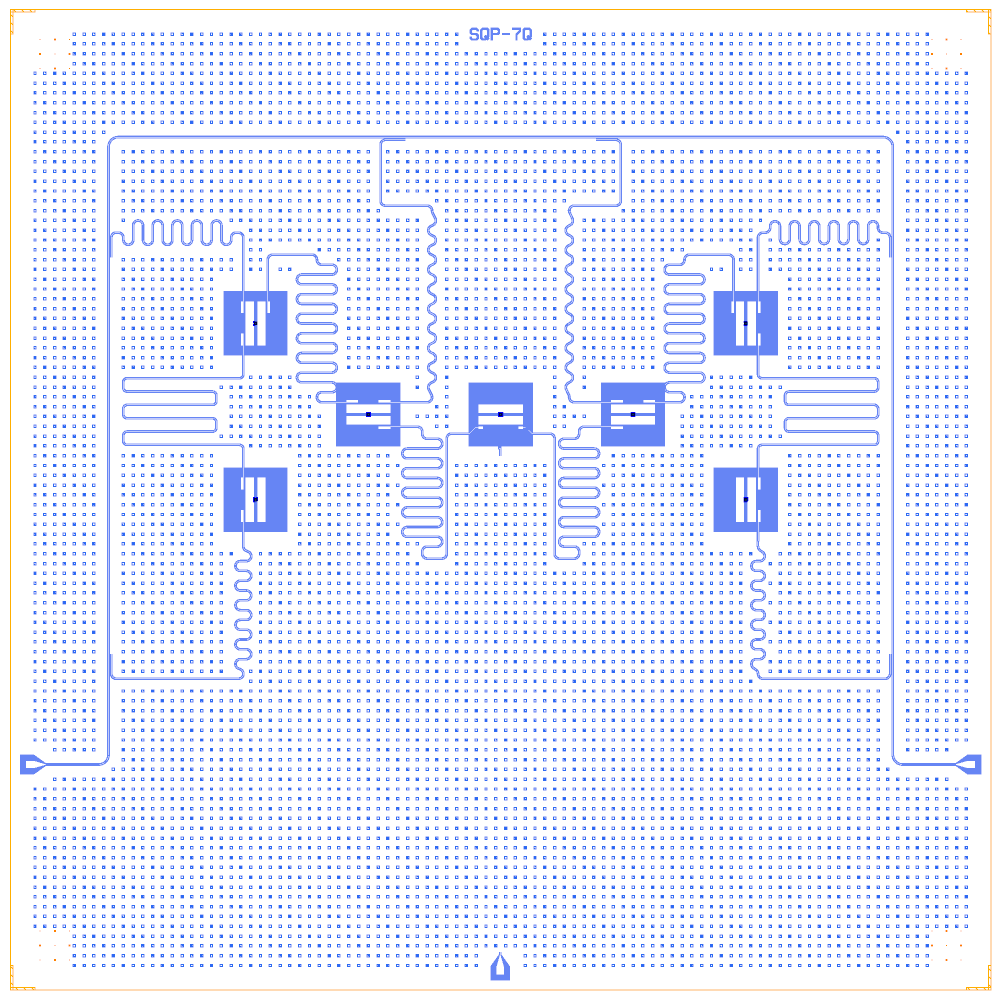

**On the chip so far:** 3 pads · 7 qubits · 0 other components · 13 routes · 0 declared couplings. **This step added** 6 route(s) `Bus_Q0_Q1`, `Bus_Q1_Q3`, `Bus_Q3_Q4`, `Bus_Q4_Q5`, `Bus_Q5_Q2`, `Bus_Q2_Q6`.

WindowsPath('examples/designs/community/seven_qubit_processor_s6_buses.png')

In [11]:
SERP = [(2375, 5560), (1150, 5560), (1150, 5696), (2100, 5696), (2100, 5832), (1150, 5832), (1150, 5968),
        (2100, 5968), (2100, 6104), (1150, 6104), (1150, 6240), (2375, 6240)]
L_SERP = 6994.03                                   # drawn path 6993.98 µm + 0.05
with d.batch():
    d.route("Bus_Q0_Q1", q["Q0"].bus_top, q["Q1"].bus_bot, meander=L_SERP, r=40, nodes=SERP)
    d.route("Bus_Q1_Q3", q["Q1"].bus_right, q["Q3"].bus_left, meander=7000, r=50,
            nodes=[(2625, 7500), (3125, 7500), (3125, 5995)])
    d.route("Bus_Q3_Q4", q["Q3"].bus_right, q["Q4"].bus_left, meander=7000, r=50,
            nodes=[(4200, 5745), (4200, 4400), (4450, 4400), (4450, 5675)])
    d.route("Bus_Q4_Q5", q["Q4"].bus_right, q["Q5"].bus_left, meander=7000, r=50,
            nodes=[(5550, 5675), (5550, 4400), (5800, 4400), (5800, 5745)])
    d.route("Bus_Q5_Q2", q["Q5"].bus_right, q["Q2"].bus_left, meander=7000, r=50,
            nodes=[(6875, 5995), (6875, 7500), (7375, 7500)])
    d.route("Bus_Q2_Q6", q["Q2"].bus_bot, q["Q6"].bus_top, meander=L_SERP, r=40,
            nodes=[(10000 - x, y) for x, y in reversed(SERP)])
layout_step(d, OUT / "seven_qubit_processor_s6_buses.png", size=(1000, 1000), width=360)

## Design 7 · Routing: Q4's charge line

**Charge line.** Q4's charge line is drawn but unrouted in the source; here it runs straight down to LP_CL. It is the chip's only control line: the source draws none for the other six qubits.

{'FL': 21858.3, 'R_Q0': 4323.2, 'R_Q1': 4260.5, 'R_Q3': 4199.7, 'R_Q5': 4140.5, 'R_Q2': 4083.0, 'R_Q6': 4027.1, 'Bus_Q0_Q1': 6994.0, 'Bus_Q1_Q3': 7000.0, 'Bus_Q3_Q4': 7000.0, 'Bus_Q4_Q5': 7000.0, 'Bus_Q5_Q2': 7000.0, 'Bus_Q2_Q6': 6994.0, 'CL_Q4': 5068.0}


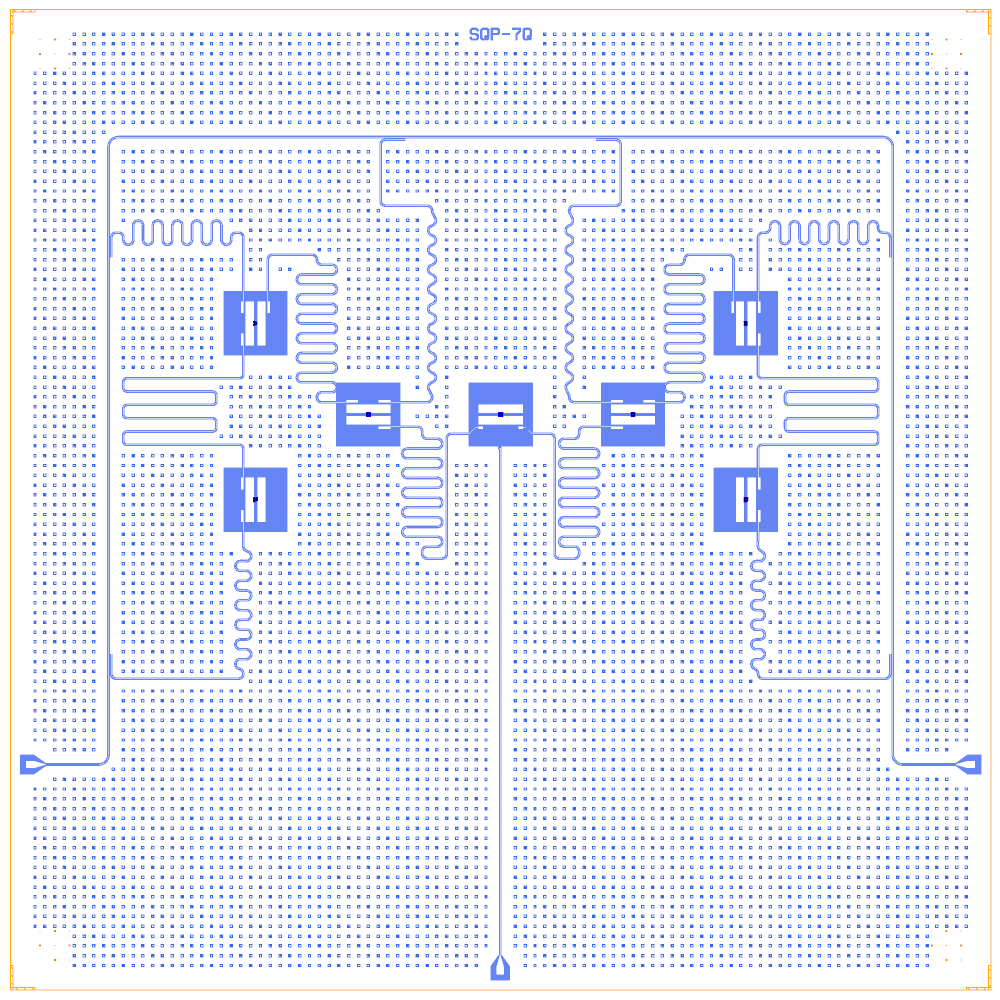

**On the chip so far:** 3 pads · 7 qubits · 0 other components · 14 routes · 0 declared couplings. **This step added** 1 route(s) `CL_Q4`.

WindowsPath('examples/designs/community/seven_qubit_processor_s7_charge_line.png')

In [12]:
with d.batch():
    d.route("CL_Q4", lp_cl.tie, q["Q4"].Charge_Line)
rebuild(d)
print({k: round(v, 1) for k, v in d.result.route_lengths().items()})
layout_step(d, OUT / "seven_qubit_processor_s7_charge_line.png", size=(1000, 1000), width=360)

## Design 8 · The whole chip: sim groups, targets, centring the core, save

**Sim groups and targets:** each qubit with its readout and the feedline (`Q0R` … `Q6R`, the default analyses:
eigenmode / EPR and Q3D C-matrix), the central chain Q3–Q4–Q5 with its two buses (Q3D only); the targets are the
staggered plan (f_q 4.80–5.20 GHz, f_r 6.8–7.3 GHz).

**Centring the core.** The PDK wants the chip content in the middle of the die. Here the qubit chain sits above the centre (as in the source)
and the feedline wraps it, so the core (qubits, buses, readouts and the feedline) is ≈ 0.5 mm high. `center_core`
measures the core's bounding box (leaving out the three launchpads, which are pinned to the die edge, and the charge-line
lead running to one of them) and shifts the whole design: instance positions, route waypoints and hanger `near` points.
The pads move along their edge with it and keep their 100 µm from it. From the v1 run: shift (0, −500) µm.

**Save.** The JSON is the deliverable. `save_design` writes it and compares it with the file it replaces (the
previous run's, the `.v1` notebook's): the segments above changed how the chip is built, not the chip, so it should say
*same design*. The file keeps the previous key order (the feedline was added before the qubits here, the buses and the charge line after the readouts), so `git diff` stays empty.

shift applied (µm): (0.0, -500.0)


| pad | cell / launcher | nearest die edge | outer etch → die edge (µm) | PDK rule |
|---|---|---|---|---|
| LP_IN | `metal:LaunchpadWirebond` | w | 100.0 | ✓ |
| LP_OUT | `metal:LaunchpadWirebond` | e | 100.0 | ✓ |
| LP_CL | `metal:LaunchpadWirebond` | s | 100.0 | ✓ |

**Same design as before:** `examples/designs/community/seven_qubit_processor.json` is identical to the file it replaces (byte for byte). The segments changed how the chip is built, not the chip.

<Designer seven_qubit_processor: 10 instances, 14 routes, live=False> → examples\designs\community\seven_qubit_processor.json


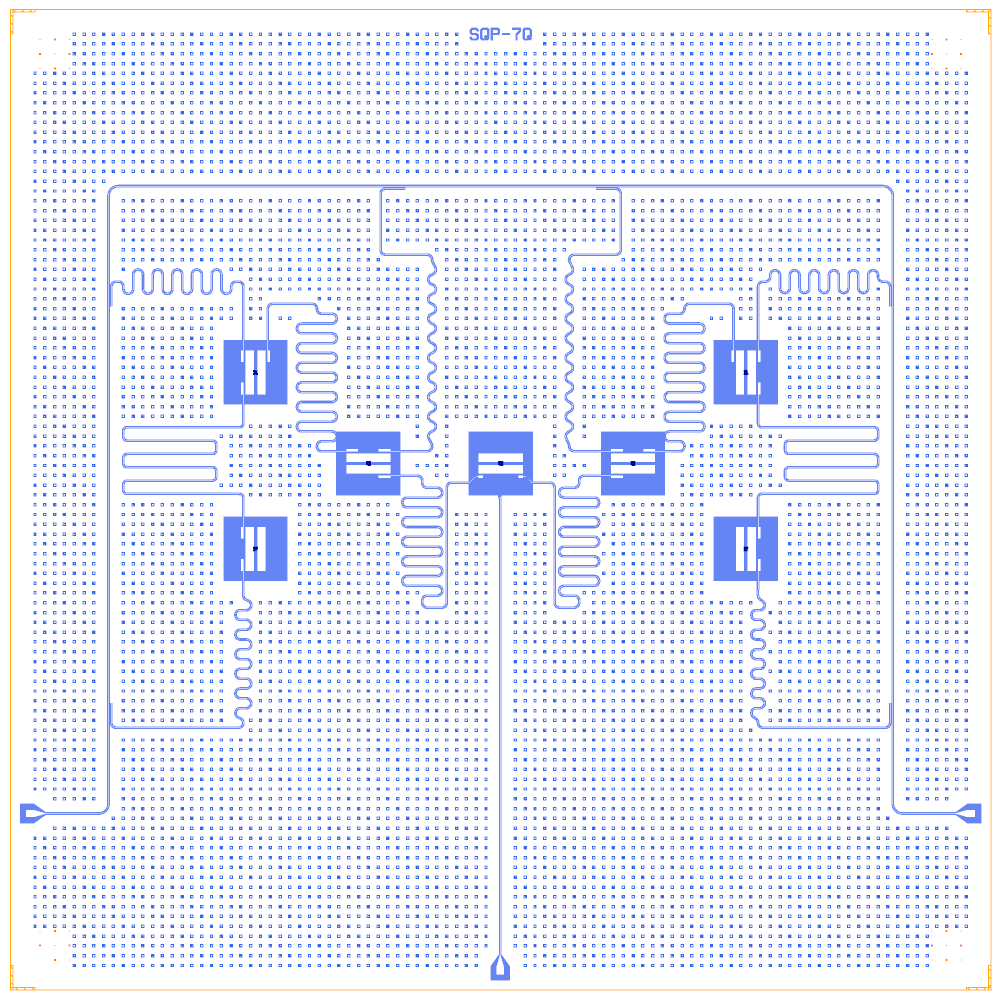

**On the chip so far:** 3 pads · 7 qubits · 0 other components · 14 routes · 0 declared couplings. **This step added** nothing new to the layout.

WindowsPath('examples/designs/community/seven_qubit_processor_routes.png')

In [13]:
with d.batch():
    for n in F_R:
        d.sim_group(f"{n}R", [n, f"R_{n}", "FL"])
    d.sim_group("Q3Q4Q5", ["Q3", "Q4", "Q5", "Bus_Q3_Q4", "Bus_Q4_Q5"], analyses=["q3d_cmatrix"])
    d.targets(**{n: {"f_q_GHz": f} for n, f in F_Q.items()}, **{f"R_{n}": {"f_GHz": f} for n, f in F_R.items()})
shift = center_core(d, skip=("LP_IN", "LP_OUT", "LP_CL", "CL_Q4"))
print("shift applied (µm):", shift)
rebuild(d)
display(Markdown(pads_md(d)))
DESIGN, same = save_design(d, OUT / "seven_qubit_processor.json")
display(Markdown(same))
print(d, "→", DESIGN)
layout_step(d, OUT / "seven_qubit_processor_routes.png", size=(1000, 1000), width=360)

# Check: DRC and netlist

The plugin's *Check* step: the design rules, then the lumped circuit the layout turns into.

## Check 1 · DRC

`d.drc()` checks connectivity (dangling ports, overlaps, route crossings, netlist opens and shorts) and the PDK margins:
- **errors** would make the chip wrong; there must be none;
- **warnings** are worth a look but can be intended: here the 14 junction attachment points (`squid_a` / `squid_b`;
  the cell draws its own junction), not route ends;
- **PDK design warnings** flag values outside the PDK margins (`pdk_rn`, `pdk_fq`, `pad_edge`, `pdk_claw`); they are
  reported, never enforced. Here: `pdk_rn` on the seven junctions (the 4.8–5.2 GHz plan).

Expected (from the v1 run): **no errors**; 14 `dangling_port` warnings (`squid_a` / `squid_b`); 7 `pdk_rn` (86.5–102.3 kΩ as
drawn). No `pad_edge`: the three launchpads sit at 100 µm.

`pdk_report(d)` sums up the PDK checks. Its content centre ((0, −850 µm) in the v1 run) includes the edge pads and Q4's charge-line
lead, which `center_core` leaves out: the core itself is centred.

In [ ]:
rebuild(d)
rep = d.drc()
display(Markdown(drc_md(rep)))
display(Markdown(pdk_report(d)))

## Check 2 · Netlist

`d.lom()` turns the layout into a lumped circuit:
- **qubits:** each pocket is a floating pair of islands with its junction, plus a node per connection pad (C_g to the
  near island, C to the far one, C to ground);
- **readouts:** each is a λ/4 `TLres` with a `HANGER` (κ) to the feedline node `FL`, which carries both 50 Ω ports;
- **buses:** each is a λ/2 `TLres` on the node joining its two pads;
- **Q4's charge line** is a `control`.

In [ ]:
lb = d.lom()
show_netlist(lb)
print(lom_summary(lb))

# LOM: simulate the lumped circuit, and plot it

## LOM 1 · The LOM simulation

First, each qubit with its readout and the feedline (QuCat normal modes, then the QuTiP dressed values), targets in
brackets. Then two coupled groups through their buses, with the static ZZ.

What the tables show (from the v1 run):
- f_q 4.766–5.165 GHz, within 2.8 % of the plan (the PDK finger grid draws Q0 / Q3 and Q5 / Q6 alike);
- f_r 6.777–7.238 GHz, within 0.9 % of 6.8–7.3 GHz;
- κ 0.125–0.152 MHz (250 µm hanger, 6 µm strip); χ −2.55 … −3.81 MHz;
- the buses' QuCat modes at 8.28–8.36 GHz; static ZZ Q0–Q1 17.6 kHz, Q3–Q4 −2.3 kHz, Q4–Q5 −4.1 kHz.

α comes out −345 … −390 MHz against the README's −280…−330 MHz, because the LOM C_Σ is below the source's 74.7 fF
(LOM 3 shows the knob that moves it).

In [ ]:
res = simulate_groups(d, {f"{n}R": [n, f"R_{n}", "FL"] for n in F_R})
display(Markdown(groups_md(res, d.data["targets"])))
pairs = simulate_groups(d, {"Q0_Q1": ["Q0", "Q1", "Bus_Q0_Q1"],
                            "Q3_Q4_Q5": ["Q3", "Q4", "Q5", "Bus_Q3_Q4", "Bus_Q4_Q5"]}, max_modes=3)
for g, r in pairs.items():
    display(Markdown(f"**{g}, QuCat normal modes:**\n\n" + modes_md(r)))
display(Markdown(zz_md(pairs)))

## LOM 2 · The LOM in two plots

The same results as pictures: (a) every normal mode of each simulated group (QuCat; circles are qubits, squares
resonators — the readouts and, in the two coupled groups, the buses; filled markers are the QuTiP dressed values; red
bars the targets), (b) the dispersive shift |χ| of each readout. From the v1 run the readouts sit within 1 % of their
red bars and the qubits within 3 %; the buses' modes near 8.3 GHz are far above both.

In [ ]:
plot_lom({**res, **pairs}, OUT / "seven_qubit_processor_lom.png", targets=d.data["targets"],
         title="seven_qubit_processor: LOM per readout pair and coupled group")

## LOM 3 · One geometry change, by hand

Before the FEM, a design step by hand. The LOM is cheap, so a design change can be checked in seconds. α is larger than the README asks because the pocket's
C_Σ is low. A taller pad adds capacitance: Q0's pads go from 90 to 130 µm high in a copy, so C_Σ rises, |α| and f_q drop,
and χ changes with the detuning from the readout. From the v1 run: f_q 4.934 → 4.549 GHz, α −390 → −322 MHz (inside the
README window), χ −2.96 → −1.60 MHz; the readout stays at 6.77 GHz. `design_copy` opens a second, non-live Designer on the saved design, so
the design file stays as it is.

In [ ]:
d2 = design_copy(DESIGN)
d2["Q0"].set(pad_height=130)
res2 = simulate_groups(d2, {"Q0R": ["Q0", "R_Q0", "FL"]})
display(Markdown(params_delta_md({"Q0R": res["Q0R"]}, res2)))

> **Simulation PC (32 GB+ RAM).** The cells below solve FEM jobs in AEDT. On this notebook's chip they need the
> simulation PC: set `RUN_FEM = True` and `FEM_FAST = False` there, run them one job at a time, and keep the results
> (`fem/`). On a smaller PC leave `RUN_FEM = False`: the cells export the jobs and load kept results only.

# Simulate: export to HFSS, the component and eigenmode simulations, the full-wave run

The plugin's *Simulate* step. The LOM above uses analytic capacitance estimates; a finite-element job measures them.
Each job is a sim group cut out of the chip, written to `build/jobs/<design>_<group>_<analysis>/`. With
`RUN_FEM = False` (the default) the jobs are only exported: the cells load results that were solved and kept before
(in `examples/designs/community/fem/<job>/`), and otherwise say what would appear.

## Simulate 1 · Export to HFSS

Three kinds of job, in self-contained folders `build/jobs/<design>_<group>_<analysis>`:
- the six qubit + readout + feedline groups as Q3D C-matrix jobs (capacitances by net name);
- the same six groups as eigenmode/EPR jobs;
- the Q3–Q4–Q5 chain with its two buses as a C-matrix job.

Exporting again replaces a folder, results included. Simulation exports never carry cheese.

`RUN_FEM = False` only exports, and the next cells load results kept from an earlier solve. `FEM_FAST` (a switch at the top) picks the fast test settings for every job exported from here on. With
`RUN_FEM = True` the next cells solve each Ansys job in a **new batch, non-graphical** AEDT 2024 R1 (or newer), so an
AEDT window you have open is never touched. Elsewhere:
`qcc hfss solve build/jobs/<job>`.

In [ ]:
FEM_FAST = fem_fast(FEM_FAST)                    # the switch from the top: fast test settings, or as written
KEEP = fem_keep_dir(DESIGN)                      # examples/designs/community/fem/: solved results are kept here
ro = [g for g in d.data["sim_groups"] if g.endswith("R")]
jobs = export_sims(DESIGN, ro + ["Q3Q4Q5"], analysis="q3d_cmatrix")
jobs_eig = export_sims(DESIGN, ro, analysis="eigenmode_epr")
display(Markdown(jobs_md(jobs) + "\n" + jobs_md(jobs_eig).split("\n", 2)[2]))

## Simulate 2 · Component simulation: the Q3D C-matrix

The capacitance of each readout group (the pocket's two pads, its connection pads, the readout and the feedline the
box cuts) and of the chain Q3–Q4–Q5 with its buses, as named nets (`Q0.island1`, `Q0.island2`, `Q0.readout`, …). Each
net is named after its LOM node, so the matrix goes straight into the circuit (Results 3). `fem_stage` solves each
job with `RUN_FEM`, else loads its kept results, else says that there are none (seven jobs, one after the other).

In [ ]:
keep_q3d = fem_stage(jobs, RUN_FEM, KEEP, force=RESOLVE, aedt=AEDT_MODE)
display(Markdown(convergence_md({f"{g} · q3d": k for g, k in keep_q3d.items()})))
for g, k in keep_q3d.items():
    if k:
        display(Markdown(cmatrix_md(k)))

## Simulate 3 · Eigenmode simulation

The six readout boxes in HFSS eigenmode: the junction is a lumped L_J ‖ C_J sheet across the pad gap, the lines the
box cuts (the feedline, the buses) end in 50 Ω, so each mode's Q gives κ. pyEPR (run inside qcc's own AEDT, never
KQC's `run_pyepr_t1_estimate.py`) turns the junction's energy participation p_J into dressed frequencies, α and χ.

In [ ]:
keep_eig = fem_stage(jobs_eig, RUN_FEM, KEEP, force=RESOLVE, aedt=AEDT_MODE)
display(Markdown(convergence_md({f"{g} · eigenmode": k for g, k in keep_eig.items()})))

## Simulate 4 · Full-wave (driven) run on the eigenmode's mesh settings

A driven HFSS run gives the S-parameters of the same box. The library cannot hand the solved eigenmode
**mesh** itself to a driven setup (no such option yet), so `driven_from_eigenmode` does the nearest honest thing: the
same sim group and box, the eigenmode job's mesh seeds (the gap and junction-island seeds that resolved the modes),
the adaptive-mesh frequency at the eigenmode's readout mode (the LOM's f_r before the eigenmode is solved) and a fast
sweep around it (0.4 GHz below to 0.2 GHz above). Here for `Q0R`: its readout is a hanger on the feedline's left leg, so S21 between
the two feedline ends the box cuts shows the notch (f_r and the external κ).

In [ ]:
f_r0 = res["Q0R"].params.get("R_Q0.f_GHz")              # the LOM's readout frequency (LOM 1)
jobs_drv = driven_from_eigenmode(DESIGN, "Q0R", jobs_eig["Q0R"][0], keep_eig["Q0R"], f_guess=f_r0)
keep_drv = fem_stage(jobs_drv, RUN_FEM, KEEP, force=RESOLVE, aedt=AEDT_MODE)
if keep_drv["Q0R"]:
    display(Markdown(driven_md(keep_drv["Q0R"])))

# Results: plot, read the values, compare with the LOM, feed back, iterate

The plugin's *Results* step: what the FEM found, against the LOM and against a target, and the design change that
moves the chip towards the target.

## Results 1 · Plot the eigenmodes

(a) each mode's frequency over the adaptive passes (how the mesh converged), (b) the final modes, frequency against
Q, coloured by the junction participation p_J (≈ 1: the qubit; ≈ 0: the readout), with the LOM's frequencies of the
same components as dashed lines. The tables below list the modes and the pyEPR values.

In [ ]:
SEL = {f"{n}R": [n, f"R_{n}", "FL"] for n in F_R}     # LOM 1's groups
PAIRS = {g: (g[:-1], f"R_{g[:-1]}", g) for g in SEL}  # sim group → (qubit, readout, LOM 1 group)
lom_f = {}
for g, (qb, rr, lg) in PAIRS.items():
    p = res[lg].params
    lom_f[qb], lom_f[rr] = p.get(f"{qb}.f_q_GHz"), p.get(f"{rr}.f_GHz")
plot_eigenmodes(keep_eig, OUT / "seven_qubit_processor_eigenmodes.png", lom=lom_f)
for g, k in keep_eig.items():
    if k:
        display(Markdown(eigen_md(k)))

## Results 2 · The values

The eigenmode jobs in the LOM's terms: each qubit's mode is the one its own junction participates in most, the
readout's the remaining mode nearest the LOM's f_r; f_q and f_r are pyEPR's dressed frequencies, α and χ its Kerr
terms, κ = f/Q of the 50 Ω-terminated box (bulk-dielectric loss removed). The driven run adds its S21 notch where it
finds one.

In [ ]:
fem_values = {}
for g, (qb, rr, lg) in PAIRS.items():
    if keep_eig.get(g):
        fem_values[g] = epr_values(keep_eig[g], {qb: rr}, {rr: lom_f[rr]})
if keep_drv["Q0R"]:
    qb, rr, _ = PAIRS["Q0R"]
    fem_values.setdefault("Q0R", {}).update(
        {f"driven {k}": v for k, v in driven_values(keep_drv["Q0R"], rr, lom_f[rr]).items()})
if fem_values:
    display(Markdown("| group | quantity | FEM |\n|---|---|---|\n" + "\n".join(
        f"| {g} | `{k}` | {v:.5g} |" for g, vals in fem_values.items() for k, v in vals.items() if k != "modes")))
else:
    print("No eigenmode results yet (RUN_FEM = True): this table would list f_q and α of each qubit and f_r, χ, κ of "
          "its readout from pyEPR, and the S21 notch of Q0's readout.")

## Results 3 · FEM against the LOM

Two comparisons per qubit. **LOM on the Q3D C-matrix:** `fill` replaces the capacitance estimates of the simulated
components by the C-matrix values (matched by net name; the other branches keep their estimates) and the same LOM
runs again. **FEM directly:** the eigenmode (pyEPR) values of Results 2. The left column is the LOM on the component
estimates (LOM 1).

Below the table: the chain Q3–Q4–Q5 with its two buses on the `Q3Q4Q5` C-matrix, the same QuCat
modes and static ZZ as LOM 1's coupled group, once that job is kept.

In [ ]:
from quantcore_circuits.circuit.fill import fill
from quantcore_circuits.lom.simulate import simulate

rows = []
for g, (qb, rr, lg) in PAIRS.items():
    lom_p = res[lg].params
    keys = [f"{qb}.f_q_GHz", f"{qb}.alpha_MHz", f"{rr}.f_GHz", f"{rr}.chi_MHz", f"{rr}.kappa_MHz"]
    if keep_q3d.get(g):
        on_fem = simulate(fill(d.lom(select=SEL[lg]).model, DESIGN, keep_q3d[g]), max_modes=2).params
        rows += [(k, lom_p.get(k), on_fem.get(k), f"{g}: LOM on the Q3D C-matrix") for k in keys]
    rows += [(k, lom_p.get(k), fem_values[g][k], f"{g}: eigenmode + pyEPR") for k in keys if k in fem_values.get(g, {})]
if rows:
    display(Markdown(fem_vs_lom_md(rows)))
else:
    print("No FEM results yet: with RUN_FEM = True this table puts f_q, α, f_r, χ and κ of the LOM next to the LOM "
          "on the Q3D C-matrix and next to the eigenmode, with the difference in %.")

CHAIN = ["Q3", "Q4", "Q5", "Bus_Q3_Q4", "Bus_Q4_Q5"]
if keep_q3d.get("Q3Q4Q5"):
    chain_fem = simulate(fill(d.lom(select=CHAIN).model, DESIGN, keep_q3d["Q3Q4Q5"]), max_modes=3)
    display(Markdown("**Q3–Q4–Q5 on the chain's C-matrix, QuCat normal modes:**\n\n" + modes_md(chain_fem)))
    display(Markdown(zz_md({"Q3_Q4_Q5 (Q3D)": chain_fem})))

## Results 4 · Feedback: one step towards the frequency plan

The design carries the staggered plan as its targets (Design 8: f_q 4.80–5.20 GHz, f_r 6.8–7.3 GHz).
`target_copy(DESIGN, {})` writes the design with them (nothing added) to `build/seven_qubit_processor_target.json`, and
the feedback works on that copy. From the v1 run the qubits are within 3 % of the plan (up to 134 MHz off, against a
± 20 MHz tolerance) and the readouts 0.3–0.9 % low, so the feedback moves every L_J and shortens every readout a
little (R_Q3 and R_Q5 run on waypoints: if the router reports "target length … shorter than the shortest path" for
them, the step was too large).

`loop.analyse` runs the estimators (QuCat, SQcircuit, scqubits, Metal LOM) on every qubit–readout pair of the
circuit — six here, so it takes minutes — on the Q3D values where a solve was kept, and picks one value per quantity
(the consensus). Q4 has no readout, so it is not a pair: its f_q target has no knob here (the notes say so).
`loop.feedback` anchors a surrogate on that point and proposes the knobs that put the targets inside their
tolerances; the proposal is written as revision 1, built and netlist-checked. **No PDK L_J bounds:** the plan needs
R_n 86–102 kΩ (Design 4, `pdk_rn`, flagged, not retuned); `pdk_lj_bounds` would pull every junction into the window,
i.e. the qubits to ≈ 6.5–7 GHz. The revision changes the LOM's L_J; to draw it, size the fingers with
`trilayer_junction("metal:TransmonPocket6", lj_nH=...)`, as Design 4 does.

In [ ]:
from quantcore_circuits import loop
from quantcore_circuits.assembly.drc import check

DESIGN_T = target_copy(DESIGN, {})               # the design's own targets (the staggered plan), nothing added
BOUNDS = None                                    # not pdk_lj_bounds(DESIGN): the plan's junctions are outside the window
FILL = [k for k in keep_q3d.values() if k] or None   # kept Q3D results fill the circuit; None: the LOM estimates
an0 = loop.analyse(str(DESIGN_T), FILL, readout=False)
display(Markdown(consensus_md(an0, only_targets=True)))
prop, rev1, rev1_build = loop.feedback(an0, design_source=str(DESIGN_T), bounds=BOUNDS)
display(Markdown(proposal_md(prop)))
now = {r.param: r.chosen for r in an0.rows}
display(Markdown(before_after_md({k: now.get(k) for k in prop.residuals}, {k: prop.predicted[k] for k in prop.residuals})))
print("revision 1:", rev1, "· DRC:", "clean" if check(rev1_build).ok else "ERRORS")

## Results 5 · Iterate to the target

The feedback cell, repeated: analyse the revision → on target? → else feed back again → the next revision, until
every target is inside its tolerance or `MAX_ITER` revisions are made (`build/seven_qubit_processor/revisions/`). Without `RUN_FEM`
each revision is judged on the LOM. With `RUN_FEM = True` the Q3D jobs of the six readout groups are exported and solved first for each revision
(`solve_rev`), so the loop closes on FEM values (each solve takes AEDT minutes). The table shows each iteration's
values against the targets and the knobs it moved; the plot the residual in tolerances (on target below 1).

In [ ]:
def solve_rev(rev, k):
    """RUN_FEM: revision k's six readout Q3D jobs, exported to build/jobs/rev<k>/ and solved (kept in fem/rev<k>/)."""
    jobs_k = {g: export_sims(rev, [g], root=f"build/jobs/rev{k}")[g] for g in ro}
    kept = fem_stage(jobs_k, RUN_FEM, KEEP / f"rev{k}", force=RESOLVE, aedt=AEDT_MODE)
    return [v for v in kept.values() if v] or None


history, last, an_last = iterate_to_target(DESIGN_T, FILL, max_iter=MAX_ITER, bounds=BOUNDS,
                                           solve=solve_rev if RUN_FEM else None, an=an0)
display(Markdown(history_md(history)))
plot_iterations(history, OUT / "seven_qubit_processor_iterate.png")
print("last design:", last, "· on target:", history[-1]["on_target"])

# Fab: the mask, snapshots, summary

## Fab 1 · Build and export

- **Design file:** `save_design(...)` wrote `examples/designs/community/seven_qubit_processor.json` (Design 8);
  `Designer.load` reopens it.
- **Fab mask with the original's cheese.** The build drew Metal's cheese (the chip's `cheese` rule, Design 1) into
  KQC's `ground_grid` layer over the free ground inside the frame's design area, so `export_fab` keeps it (`cheese
  source: build`, no PDK band added) and writes only the PDK fab layers, with corner rounding; every hole is on 3/0
  as well as on 1/0. The 25 µm clearance is measured from the 3/0 keep-out, which already adds the PDK route margin
  (10 µm) round each CPW, so the holes sit 10 µm further from the line etch than in Metal. `qcc mask` keeps it too. In the v1 run: 7260
  holes.
- **Simulation export options:** `build_simulation(design, group, analysis, airbridges=True)` keeps airbridges in a FEM
  export (this chip has none); cheese is never exported.
- **The same from the command line:** `qcc build examples/designs/community/seven_qubit_processor.json`,
  `qcc design drc …`, `qcc mask …` (the fab file,
  with the build's cheese), `qcc sim build … -g Q0R -a q3d_cmatrix`, `qcc hfss solve build/jobs/<job>`.

In [ ]:
rebuild(d)
FAB = Path("build") / "seven_qubit_processor_fab.oas"
display(Markdown(fab_layers_md(d, path=FAB, cheese=True, rounding=True)))   # keeps the build's Metal cheese

## Fab 2 · Snapshots

- the full chip, to compare with the source's GUI screenshot `simon_7qubit_gui_live_full.png`: the same U chain; the ∩
  feedline and three launchpads replace the six readout pads;
- the central row Q3–Q4–Q5 with the bus hairpins;
- the Q0–Q1 serpentine bus;
- Q4's trilayer junction;
- the fab mask round Q0 and its hanger: the 25 µm holes of the original's cheese (on 1/0 and on 3/0), clear
  of the 3/0 keep-outs.

In [ ]:
snap(d, OUT / "seven_qubit_processor.png", size=(1600, 1600))
dy = shift[1]
snap(d, OUT / "seven_qubit_processor_chain.png", box=(3100, 4300 + dy, 6900, 6400 + dy), size=(1520, 840), width=640)
snap(d, OUT / "seven_qubit_processor_q0q1.png", box=(1000, 4500 + dy, 3000, 7400 + dy), size=(800, 1160), width=320)
snap(d, OUT / "seven_qubit_processor_jj.png", box=(4960, 5830 + dy, 5040, 5910 + dy), width=300)
snap_file(FAB, OUT / "seven_qubit_processor_cheese.png", box=(700, 2600 + dy, 2900, 4800 + dy), size=(1000, 1000), width=400);

## Summary

- **Matches the source:** the qubit cells and options, positions and orientations, the U chain and its 7 mm buses, Q4's
  charge line, the original's Metal cheese (drawn by the build, kept in the mask: 7260 holes in the v1 run).
- **Changed or added:** λ/4 hangers on a ∩ feedline instead of galvanic readout meanders (the source has no
  resonators), three launchpads instead of six readout pads; the PDK frame, sapphire, trilayer junctions; the pads 100 µm
  from the die edge; the core centred in the die (shifted down 500 µm).
- **Open PDK design warnings:** `pdk_rn` on all seven junctions (86–102 kΩ for the 4.8–5.2 GHz plan; flagged, not
  retuned). f_q within 2.8 % of the plan, f_r within 0.9 % (from the v1 run).
- **Known LOM limits:** α is above the README window (low pocket C_Σ in the LOM); the Q3D jobs replace the estimate.
- **Layout:** built in segments (die, pads, the feedline, the qubits, the readouts, the buses, the charge line, the whole chip); the saved JSON is the v1 notebook's.
- **Feedback:** towards the design's own plan on a copy: `loop.analyse` → `loop.feedback` → revisions until on target (LOM; FEM with `RUN_FEM`); no PDK L_J bounds (the plan's junctions are outside the window).
- **Open:** the FEM jobs (Q3D, eigenmode, driven) are exported, not solved (`RUN_FEM = False`): run with `RUN_FEM = True` to fill the Simulate and Results cells.